# Computational Intelligence Project
# Exercise 8. Evolution of cooperation

**Question:** Does cooperation emerge and persist as action noise increases?

**Hypothesis:** Higher noise reduces cooperation over generations 401–500.

In [1]:
import random

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from ipd import (
    SETTINGS, STRATEGIES, BITS, LABELS, NAMES,
    expected_match, simulate_match, build_matrices, make_toolbox, evaluate_population,
)
from run_experiment import (
    NOISE_LEVELS, PILOT_RUNS, run_study, get_values, pilot_spread, read_matrix,
    load_results, make_comparisons, plot_matrix, plot_outcomes,
    plot_strategy_frequencies, plot_final_window, plot_classical_payoffs,
)

%matplotlib inline

def show(figure):
    display(figure)
    plt.close(figure)

for name, value in SETTINGS.items():
    print(name, "=", value)

population = 100
generations = 500
rounds = 150
crossover_probability = 0.7
crossover_bit_probability = 0.5
mutation_bit_probability = 0.01
tournament_size = 3
elites = 2
final_window = 100


## 32 strategies

**0 = cooperate**, **1 = defect**.

| Gene | Meaning |
|---|---|
| 0 | First action |
| 1 | Next action after CC |
| 2 | Next action after CD |
| 3 | Next action after DC |
| 4 | Next action after DD |

Own move comes first, so if I see CD, my opponent sees DC.
There are 32 strategies and 100 individuals, so many individuals share a strategy.

In [2]:
print("ID  Bits   Name")
for i, bits in enumerate(BITS):
    print(f"{i:02d}  {bits}  {NAMES.get(i, '')}")

ID  Bits   Name
00  00000  ALLC
01  00001  
02  00010  
03  00011  
04  00100  
05  00101  TFT
06  00110  PAVLOV
07  00111  GRIM
08  01000  
09  01001  
10  01010  
11  01011  
12  01100  
13  01101  
14  01110  
15  01111  
16  10000  
17  10001  
18  10010  
19  10011  
20  10100  
21  10101  
22  10110  
23  10111  
24  11000  
25  11001  
26  11010  
27  11011  
28  11100  
29  11101  
30  11110  
31  11111  ALLD


## Payoff A and cooperation H

**A[i, j]** is the expected payoff per round of strategy i against j.
Rewards for CC, CD, DC, DD are **3, 0, 5, 1**.

**H[i, j]** is the share of cooperative moves in the match.
CC counts as 1, CD and DC as 0.5, DD as 0.

For example, ALLC against ALLD gets A = 0 and H = 0.5.

In [3]:
pairs = [(0, 0), (0, 31), (31, 0), (31, 31), (5, 31)]

for first, second in pairs:
    a, h = expected_match(STRATEGIES[first], STRATEGIES[second], noise=0)
    print(f"{LABELS[first]} vs {LABELS[second]}: A={a:.4f}, H={h:.4f}")

00: 00000 ("ALLC") vs 00: 00000 ("ALLC"): A=3.0000, H=1.0000
00: 00000 ("ALLC") vs 31: 11111 ("ALLD"): A=0.0000, H=0.5000
31: 11111 ("ALLD") vs 00: 00000 ("ALLC"): A=5.0000, H=0.5000
31: 11111 ("ALLD") vs 31: 11111 ("ALLD"): A=1.0000, H=0.0000
05: 00101 ("TFT") vs 31: 11111 ("ALLD"): A=0.9933, H=0.0033


## Computing the matrices

For each pair of strategies:

1. Take the first move of each one.
2. Add the chance of a mistake to get the chances of CC, CD, DC and DD.
3. Use each strategy's response to get the next round.
4. Repeat for 150 rounds and add up the points and cooperation.
5. Divide by 150.

We do this for all 32 × 32 pairs at noise 0, 0.01 and 0.05.
Below we also check the result by simulating real matches.

In [4]:
matrices = {}
for noise in NOISE_LEVELS:
    matrices[noise] = build_matrices(noise, rounds=SETTINGS["rounds"])

In [5]:
# 10000 random TFT vs TFT matches at noise 0.01
payoffs, cooperation = simulate_match(STRATEGIES[5], STRATEGIES[5], noise=0.01, matches=10000, seed=123)
expected_a, expected_h = expected_match(STRATEGIES[5], STRATEGIES[5], noise=0.01)

print("Simulated average payoff:", round(np.mean(payoffs), 4))
print("Calculated payoff:", round(expected_a, 4))
print("Simulated cooperation:", round(np.mean(cooperation), 4))
print("Calculated cooperation:", round(expected_h, 4))

Simulated average payoff: 2.5247
Calculated payoff: 2.5206
Simulated cooperation: 0.6582
Calculated cooperation: 0.6554


## Inspect a matrix entry

Noise 0.01, TFT (row 5) against PAVLOV (column 6).

05: 00101 ("TFT") against 06: 00110 ("PAVLOV")
Expected payoff A: 2.4291208369162445
Cooperation H: 0.6203536616374816


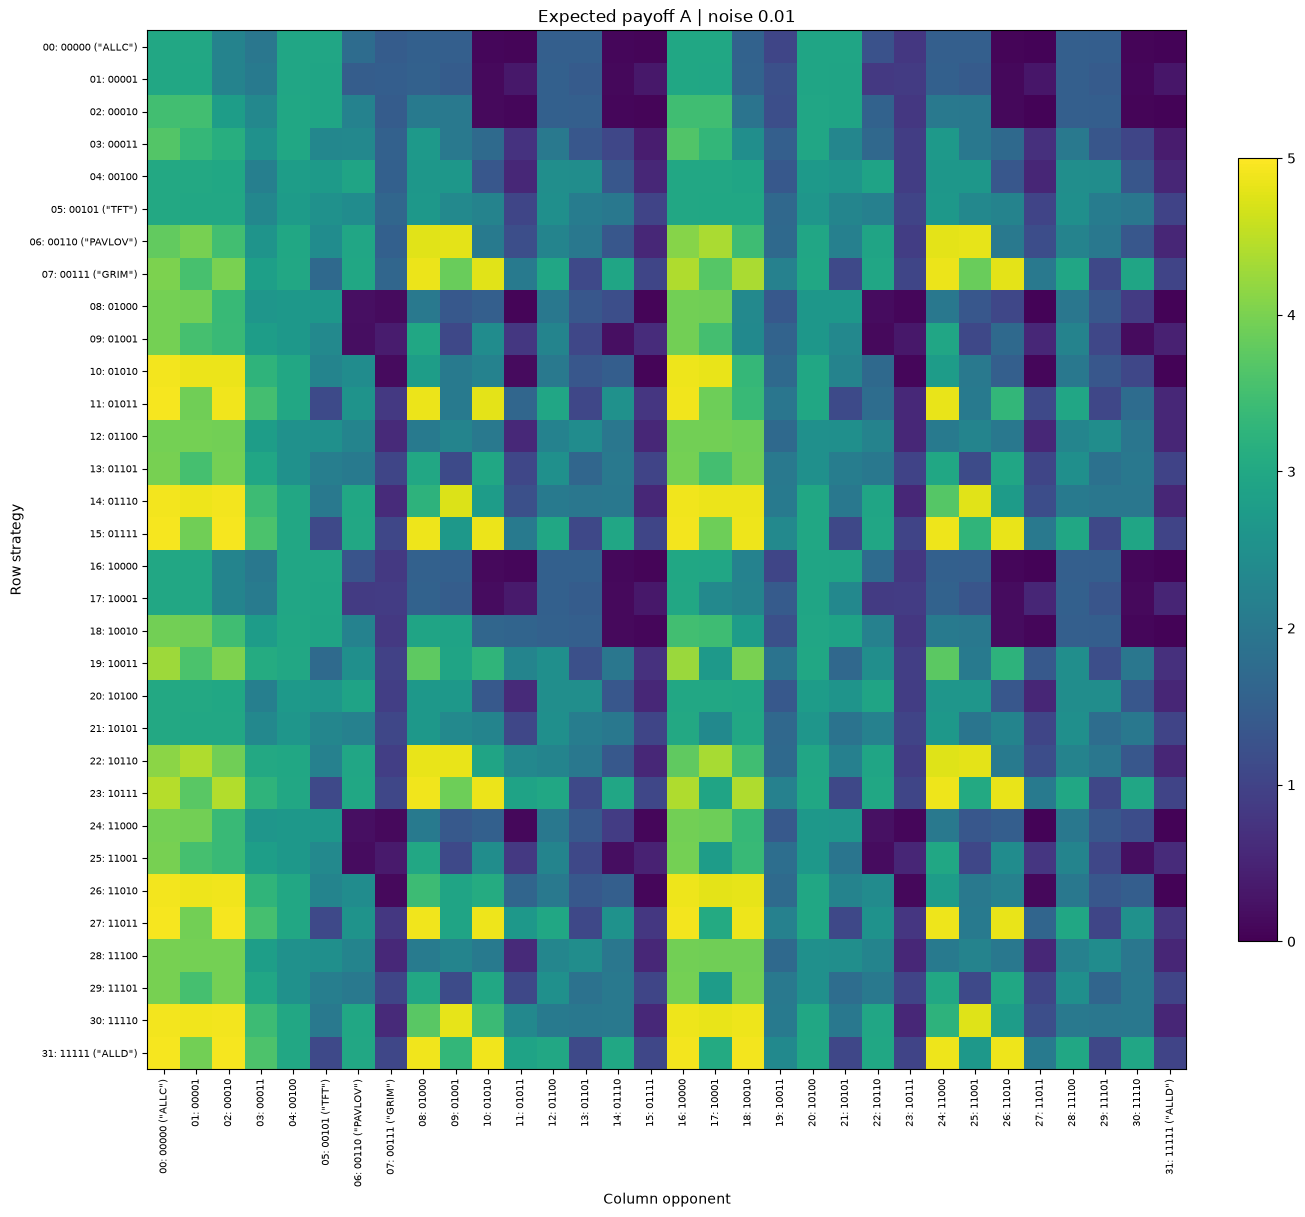

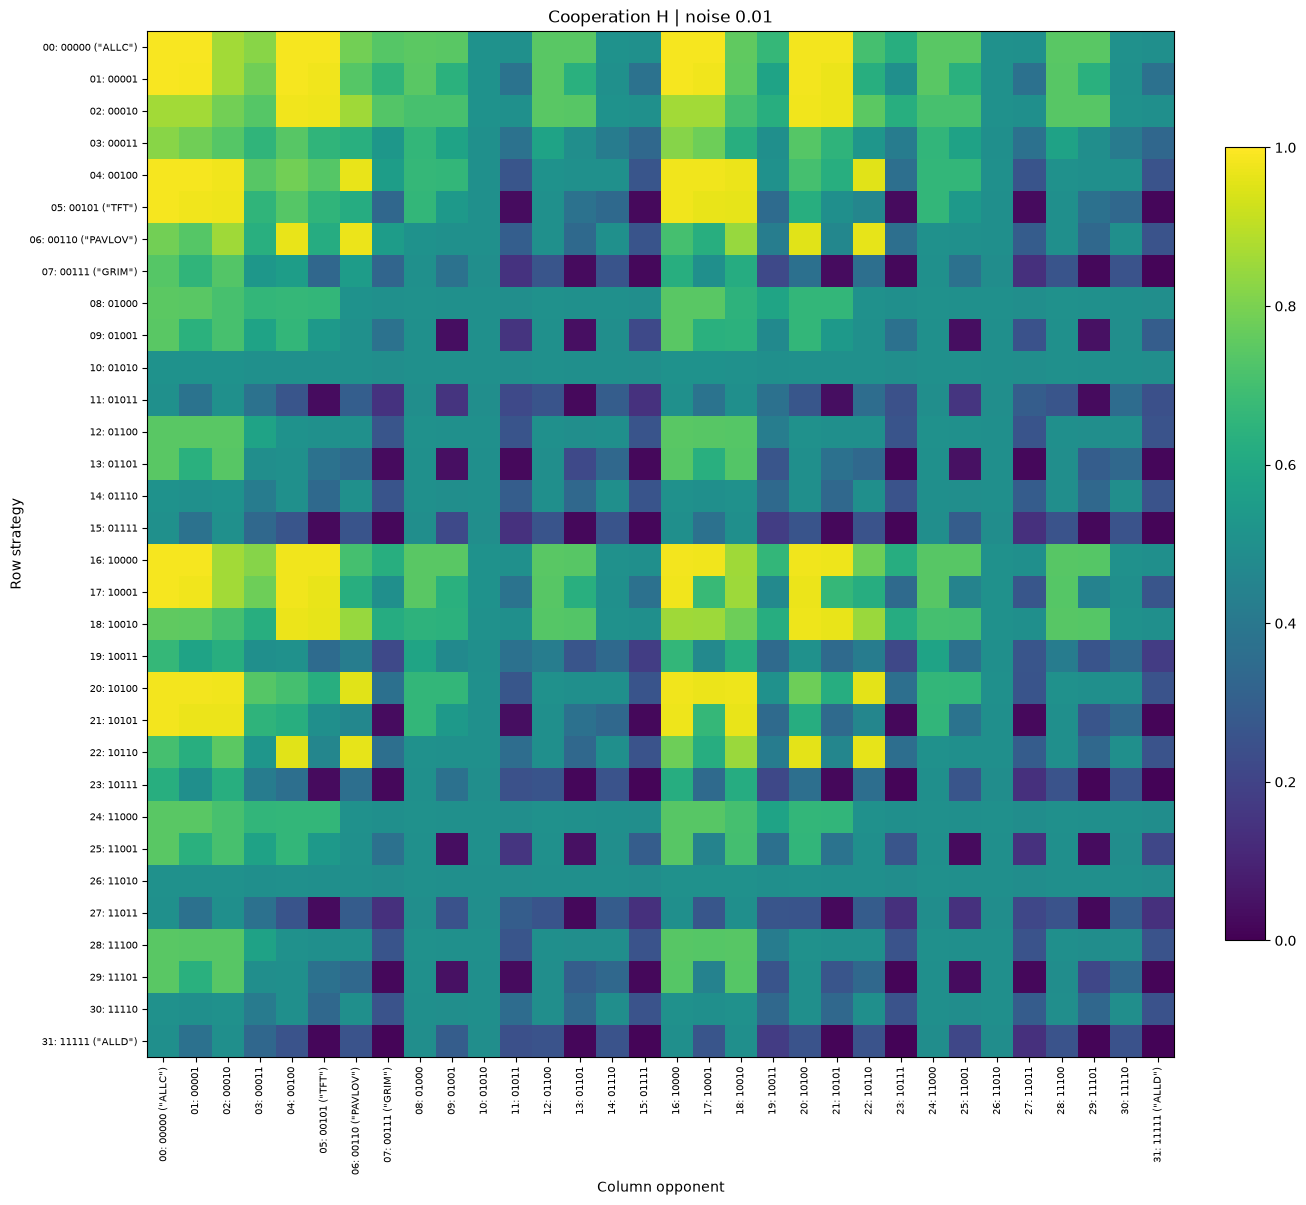

In [6]:
noise = 0.01
row_id, column_id = 5, 6  # TFT vs PAVLOV
A, H = matrices[noise]

print(LABELS[row_id], "against", LABELS[column_id])
print("Expected payoff A:", A[row_id, column_id])
print("Cooperation H:", H[row_id, column_id])

show(plot_matrix(A, noise, "A"))
show(plot_matrix(H, noise, "H"))

## Create and evaluate 100 individuals

An individual is a list of five bits. DEAP stores its fitness with it.
The toolbox has the functions for creating individuals, selection, crossover and mutation.

Fitness is the average payoff against the other 99 individuals:

`fitness = (A[i] @ counts - A[i, i]) / 99`

`A[i] @ counts` sums the payoff against each strategy, weighted by how many use it.
We subtract `A[i, i]` because nobody plays against themselves.

For example, one ALLD among 99 ALLC gets fitness 5 without noise. Among 99 ALLD it gets 1.

In [7]:
random.seed(42)

toolbox = make_toolbox()
population = toolbox.population(n=SETTINGS["population"])
counts, payoff, cooperation = evaluate_population(population, A, H)

for individual in population:
    print(list(individual), "fitness:", round(individual.fitness.values[0], 4))

print("Population mean payoff:", round(payoff, 4))
print("Population cooperation (%):", round(cooperation * 100, 2))

parents = toolbox.select(population, 2)
print("Two selected parents:", [list(parent) for parent in parents])

[0, 0, 1, 0, 0] fitness: 2.0965
[0, 0, 0, 1, 0] fitness: 1.7113
[0, 0, 0, 0, 0] fitness: 1.5449
[0, 1, 0, 1, 1] fitness: 2.5615
[0, 0, 1, 1, 1] fitness: 2.8806
[0, 0, 1, 0, 0] fitness: 2.0965
[1, 0, 1, 1, 1] fitness: 2.8981
[0, 1, 0, 1, 0] fitness: 2.0966
[1, 1, 0, 0, 0] fitness: 1.7422
[0, 1, 0, 0, 0] fitness: 1.7086
[1, 1, 1, 1, 0] fitness: 2.7493
[1, 1, 0, 1, 0] fitness: 2.3441
[0, 0, 0, 1, 1] fitness: 2.0106
[1, 0, 1, 0, 0] fitness: 2.0647
[0, 1, 1, 1, 0] fitness: 2.6556
[0, 1, 0, 1, 1] fitness: 2.5615
[1, 0, 1, 0, 0] fitness: 2.0647
[1, 1, 1, 1, 0] fitness: 2.7493
[0, 1, 0, 0, 0] fitness: 1.7086
[0, 0, 1, 0, 1] fitness: 2.1984
[1, 1, 1, 0, 0] fitness: 2.1432
[1, 1, 0, 1, 1] fitness: 2.7922
[0, 1, 0, 1, 0] fitness: 2.0966
[0, 1, 0, 0, 1] fitness: 1.8134
[0, 0, 1, 1, 0] fitness: 2.5619
[0, 1, 1, 0, 0] fitness: 2.137
[0, 0, 0, 1, 0] fitness: 1.7113
[0, 0, 1, 0, 1] fitness: 2.1984
[1, 0, 0, 1, 1] fitness: 2.478
[1, 1, 1, 0, 0] fitness: 2.1432
[0, 0, 1, 0, 0] fitness: 2.0965
[0, 0, 0, 

## The evolution loop

Start with 100 random individuals, then for each generation:

1. Everyone plays the other 99 and gets a fitness.
2. Save payoff, cooperation and strategy counts.
3. Copy the 2 best individuals to the next generation.
4. Select parents for the other 98 places, then apply crossover and mutation.

Fitness is recomputed every generation, since the opponents change.
Mutation flips each bit with a 1% chance. We run 500 generations.

In [8]:
live_histories, live_summaries, live_matrices = run_study(runs=1, matrices=matrices)

Noise 0: finished 1 run(s).
Noise 0.01: finished 1 run(s).
Noise 0.05: finished 1 run(s).


## Results of the live runs

One run per noise level, 100 individuals, 500 generations.
The table shows the average of the last 100 generations.
The plots show cooperation and payoff over time, and which strategies spread.

Noise | Cooperation (%) | Payoff per round
0 | 97.98 | 2.9782
0.01 | 49.02 | 2.0676
0.05 | 22.53 | 1.5246

Final counts at noise 0.0
00: 00000 ("ALLC") count: 0
01: 00001 count: 0
02: 00010 count: 0
03: 00011 count: 0
04: 00100 count: 15
05: 00101 ("TFT") count: 84
06: 00110 ("PAVLOV") count: 0
07: 00111 ("GRIM") count: 0
08: 01000 count: 0
09: 01001 count: 0
10: 01010 count: 0
11: 01011 count: 0
12: 01100 count: 0
13: 01101 count: 0
14: 01110 count: 0
15: 01111 count: 0
16: 10000 count: 0
17: 10001 count: 0
18: 10010 count: 0
19: 10011 count: 0
20: 10100 count: 0
21: 10101 count: 1
22: 10110 count: 0
23: 10111 count: 0
24: 11000 count: 0
25: 11001 count: 0
26: 11010 count: 0
27: 11011 count: 0
28: 11100 count: 0
29: 11101 count: 0
30: 11110 count: 0
31: 11111 ("ALLD") count: 0


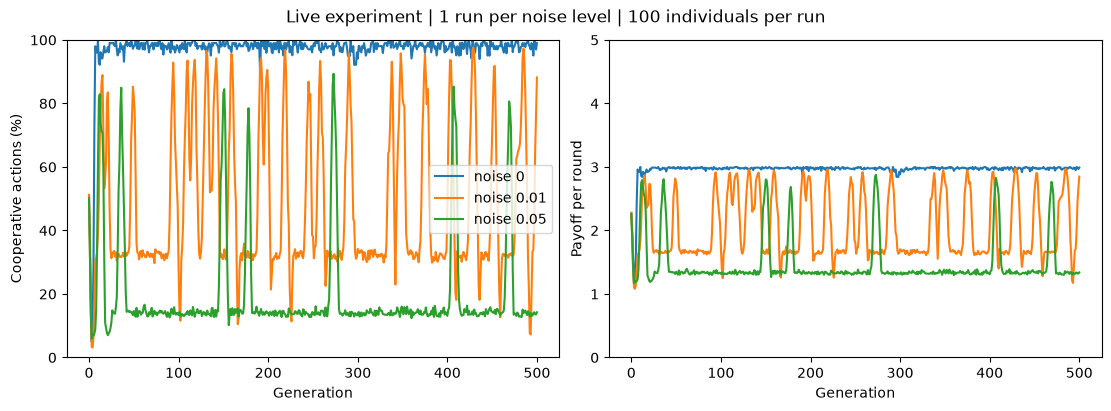

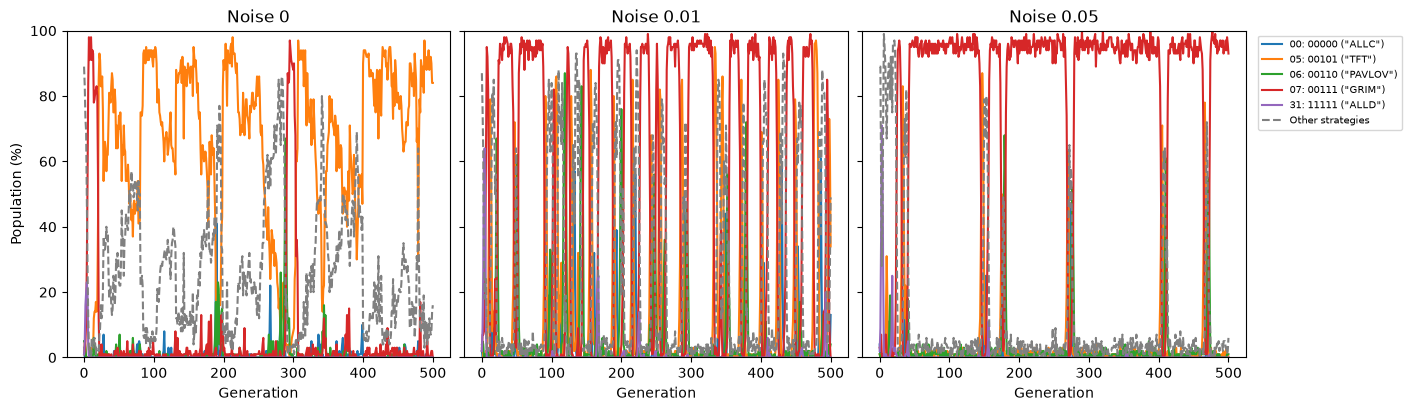

In [9]:
print("Noise | Cooperation (%) | Payoff per round")
for row in live_summaries:
    print(f"{row['noise']:g} | {row['window_cooperation'] * 100:.2f} | {row['window_payoff']:.4f}")

first_run = live_summaries[0]
print("\nFinal counts at noise", first_run["noise"])
for i, bits in enumerate(BITS):
    print(LABELS[i], "count:", first_run[f"final_count_{bits}"])

show(plot_outcomes(live_histories))
show(plot_strategy_frequencies(live_histories))

The full study is already saved in results/.

In [10]:
noise = 0.01
row_id, column_id = 5, 6

labels, saved_A = read_matrix(f"results/A_noise_{noise:g}.csv")
labels, saved_H = read_matrix(f"results/H_noise_{noise:g}.csv")

print(labels[row_id], "against", labels[column_id])
print("Saved payoff A:", saved_A[row_id, column_id])
print("Saved cooperation H:", saved_H[row_id, column_id])

05: 00101 ("TFT") against 06: 00110 ("PAVLOV")
Saved payoff A: 2.4291208369162445
Saved cooperation H: 0.6203536616374816


## The full study

**30 runs per noise level**, each with 100 individuals and 500 generations.
For each noise level we take the median of the 30 runs.

In [11]:
study_histories, summaries, study_matrices = load_results("results")

first_run = summaries[0]
print("Noise:", first_run["noise"])
print("Run:", int(first_run["run"]))
print("Seed:", int(first_run["seed"]))
for i, bits in enumerate(BITS):
    print(LABELS[i], "final count:", int(first_run[f"final_count_{bits}"]))

print("\nNoise | Runs | Median cooperation (%) | Median payoff")
for noise in NOISE_LEVELS:
    cooperation = np.median(get_values(summaries, noise, "window_cooperation")) * 100
    payoff = np.median(get_values(summaries, noise, "window_payoff"))
    runs = len(get_values(summaries, noise, "window_payoff"))
    print(f"{noise:g} | {runs} | {cooperation:.2f} | {payoff:.4f}")

Noise: 0.0
Run: 1
Seed: 21261112
00: 00000 ("ALLC") final count: 0
01: 00001 final count: 0
02: 00010 final count: 0
03: 00011 final count: 0
04: 00100 final count: 15
05: 00101 ("TFT") final count: 84
06: 00110 ("PAVLOV") final count: 0
07: 00111 ("GRIM") final count: 0
08: 01000 final count: 0
09: 01001 final count: 0
10: 01010 final count: 0
11: 01011 final count: 0
12: 01100 final count: 0
13: 01101 final count: 0
14: 01110 final count: 0
15: 01111 final count: 0
16: 10000 final count: 0
17: 10001 final count: 0
18: 10010 final count: 0
19: 10011 final count: 0
20: 10100 final count: 0
21: 10101 final count: 1
22: 10110 final count: 0
23: 10111 final count: 0
24: 11000 final count: 0
25: 11001 final count: 0
26: 11010 final count: 0
27: 11011 final count: 0
28: 11100 final count: 0
29: 11101 final count: 0
30: 11110 final count: 0
31: 11111 ("ALLD") final count: 0

Noise | Runs | Median cooperation (%) | Median payoff
0 | 30 | 97.99 | 2.9777
0.01 | 30 | 47.18 | 2.0195
0.05 | 30 | 9

## Results of the full study

The line is the median of the 30 runs. The shaded area goes from the lowest to the highest run.

In the last plot, each dot is one run's average over generations 401–500. The black bar is the median.

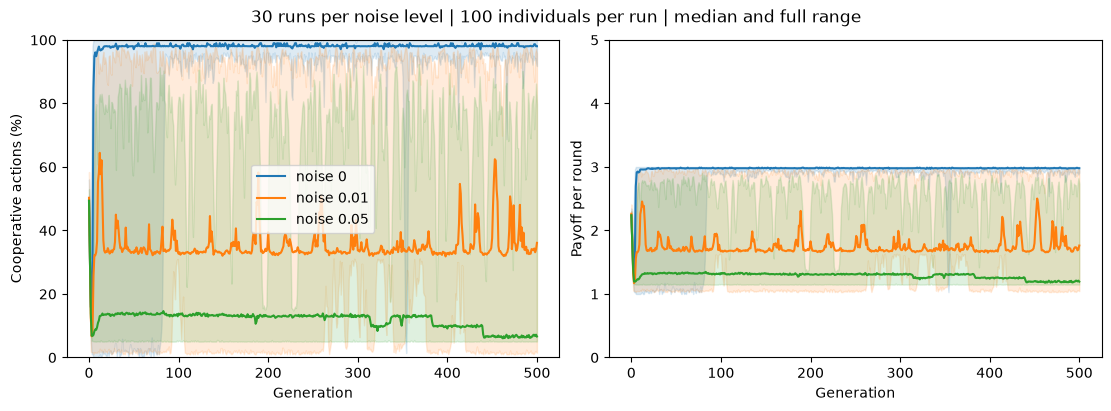

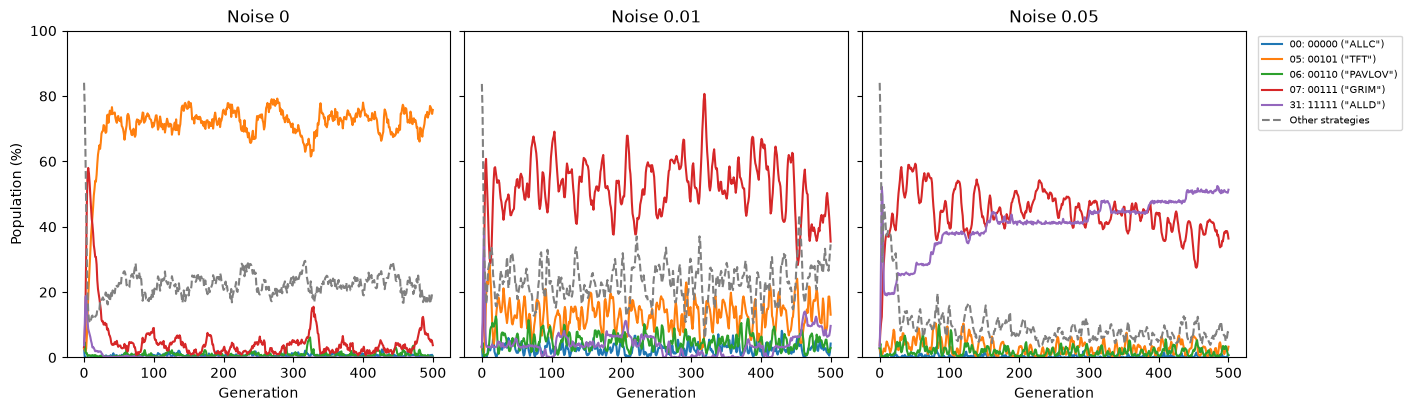

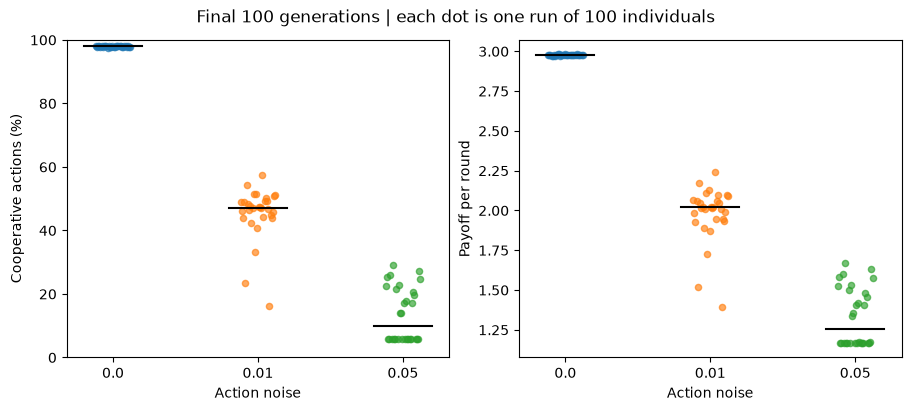

In [12]:
show(plot_outcomes(study_histories))
show(plot_strategy_frequencies(study_histories))
show(plot_final_window(summaries))

## Differences and uncertainty

We compare 0 vs 0.01, 0 vs 0.05 and 0.01 vs 0.05.
Differences are noisier minus less noisy, so a negative value means less cooperation.

- **Bootstrap 95% interval.** We resample the 30 runs with replacement 5000 times
  and take the middle 95% of the median differences. No new evolution is run.
- **Mann–Whitney test.** The runs are independent (different seeds), so we use this test.
- **Vargha–Delaney A12.** The chance that a noisy run beats a reference run (ties count half).
  0.5 means no difference. |A12 − 0.5| above 0.21 is a large effect.
- **Holm correction.** We run 6 tests (3 pairs × 2 measures), so `holm_p` corrects for that.

In [13]:
for row in make_comparisons(summaries):
    effect, low, high = row["median_difference"], row["ci95_low"], row["ci95_high"]
    if row["measure"] == "window_cooperation":
        effect, low, high = effect * 100, low * 100, high * 100
        unit = "percentage points of cooperation"
    else:
        unit = "payoff points per round"

    print(f"Noise {row['treatment_noise']:g} minus noise {row['reference_noise']:g}")
    print(f"Difference: {effect:.2f} {unit}")
    print(f"95% interval: {low:.2f} to {high:.2f}")
    print(f"Mann-Whitney p = {row['mann_whitney_p']:.2g} (Holm {row['holm_p']:.2g}), A12 = {row['vargha_delaney_A12']:.2f}\n")

Noise 0.01 minus noise 0
Difference: -50.81 percentage points of cooperation
95% interval: -52.26 to -48.89
Mann-Whitney p = 3e-11 (Holm 1.8e-10), A12 = 0.00

Noise 0.05 minus noise 0
Difference: -88.03 percentage points of cooperation
95% interval: -92.26 to -79.15
Mann-Whitney p = 3e-11 (Holm 1.8e-10), A12 = 0.00

Noise 0.05 minus noise 0.01
Difference: -37.22 percentage points of cooperation
95% interval: -42.83 to -28.10
Mann-Whitney p = 1.8e-10 (Holm 3.6e-10), A12 = 0.02

Noise 0.01 minus noise 0
Difference: -0.96 payoff points per round
95% interval: -0.99 to -0.92
Mann-Whitney p = 3e-11 (Holm 1.8e-10), A12 = 0.00

Noise 0.05 minus noise 0
Difference: -1.72 payoff points per round
95% interval: -1.81 to -1.54
Mann-Whitney p = 3e-11 (Holm 1.8e-10), A12 = 0.00

Noise 0.05 minus noise 0.01
Difference: -0.77 payoff points per round
95% interval: -0.88 to -0.57
Mann-Whitney p = 2.2e-10 (Holm 3.6e-10), A12 = 0.02



## How many runs? The pilot

We treat the first 10 runs of each noise level as a pilot.
They are part of the 30 runs, so this is only a rough check.
If the spread within a noise level (IQR) is small compared to the gaps between levels,
a few runs are enough. We still use 30 so the intervals are narrow,
especially for 0.01 vs 0.05.

In [14]:
# Cooperation spread (%): first 10 runs vs all 30
print("Noise | Sample | Runs | Median | IQR | Min | Max")
for row in pilot_spread(summaries):
    if row["measure"] == "window_cooperation":
        print(f"{row['noise']:g} | {row['sample']} | {row['runs']} | {row['median'] * 100:.1f} | "
              f"{row['iqr'] * 100:.1f} | {row['min'] * 100:.1f} | {row['max'] * 100:.1f}")

print("\nPilot only (first", PILOT_RUNS, "runs per condition):")
for row in make_comparisons(summaries, max_runs=PILOT_RUNS):
    if row["measure"] == "window_cooperation":
        print(f"{row['treatment_noise']:g} vs {row['reference_noise']:g}: "
              f"{row['median_difference'] * 100:.1f} pp "
              f"[{row['ci95_low'] * 100:.1f}, {row['ci95_high'] * 100:.1f}], "
              f"p = {row['mann_whitney_p']:.2g}, A12 = {row['vargha_delaney_A12']:.2f}")

Noise | Sample | Runs | Median | IQR | Min | Max
0 | pilot | 10 | 98.0 | 0.2 | 97.8 | 98.2
0 | full | 30 | 98.0 | 0.3 | 97.6 | 98.2
0.01 | pilot | 10 | 47.1 | 4.4 | 23.5 | 54.4
0.01 | full | 30 | 47.2 | 4.9 | 16.3 | 57.5
0.05 | pilot | 10 | 13.6 | 18.8 | 5.7 | 29.2
0.05 | full | 30 | 10.0 | 15.5 | 5.7 | 29.2

Pilot only (first 10 runs per condition):
0.01 vs 0: -50.8 pp [-54.1, -49.0], p = 0.00018, A12 = 0.00
0.05 vs 0: -84.4 pp [-92.4, -72.7], p = 0.00018, A12 = 0.00
0.05 vs 0.01: -33.5 pp [-42.9, -21.1], p = 0.00044, A12 = 0.03


## Strategy counts

The most common strategies over the last 100 generations of the saved runs.


Noise 0: average number of individuals, out of 100
05: 00101 ("TFT") 72.08
04: 00100 17.35
07: 00111 ("GRIM") 3.75
01: 00001 2.86
06: 00110 ("PAVLOV") 1.06

Noise 0.01: average number of individuals, out of 100
07: 00111 ("GRIM") 48.45
05: 00101 ("TFT") 13.79
31: 11111 ("ALLD") 6.13
01: 00001 6.05
04: 00100 5.65

Noise 0.05: average number of individuals, out of 100
31: 11111 ("ALLD") 49.63
07: 00111 ("GRIM") 38.13
05: 00101 ("TFT") 2.83
06: 00110 ("PAVLOV") 1.79
04: 00100 1.33


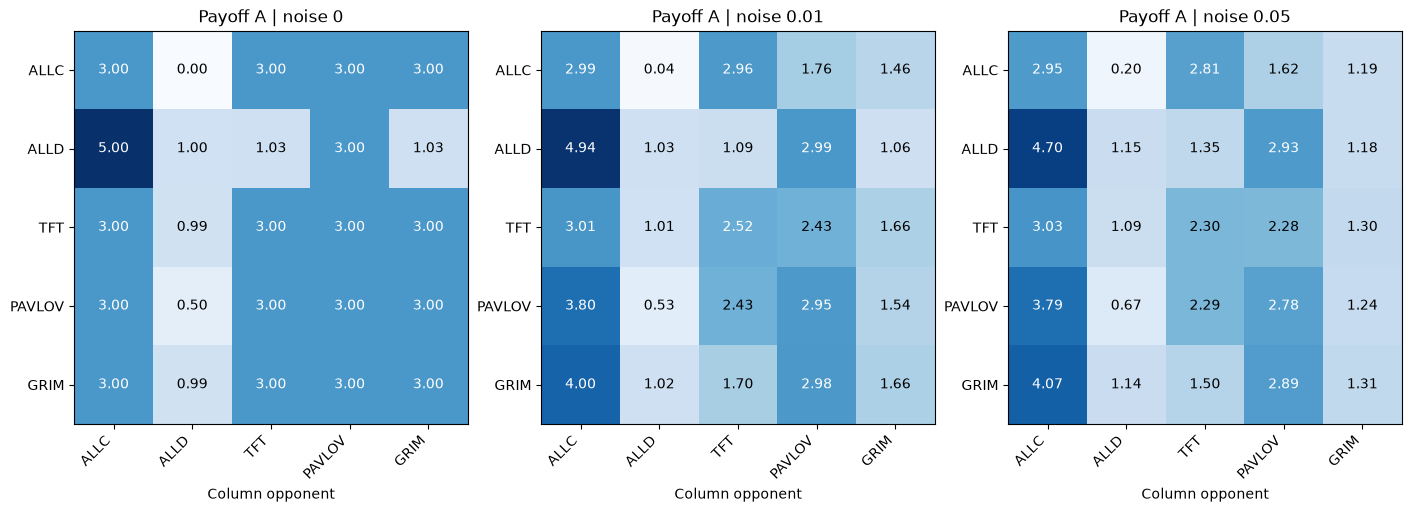

In [15]:
for noise in NOISE_LEVELS:
    mean_counts = []
    for bits in BITS:
        values = get_values(summaries, noise, f"window_mean_count_{bits}")
        mean_counts.append(np.mean(values))
    most_common = np.argsort(mean_counts)[::-1][:5]

    print(f"\nNoise {noise:g}: average number of individuals, out of 100")
    for i in most_common:
        print(LABELS[i], round(mean_counts[i], 2))

show(plot_classical_payoffs(matrices))